# TASK AIS-2 -- historical AIS track preparation/validation

**Scope: preparation/validation only.** Uses `iste.ais_data` (new, unmodified by
any later cell here) to inspect, filter, and validate the real historical AIS CSV
(`east_med_massive_random_ais.csv`, 124,887 rows, ~2,003 MMSI) against the June
2019 event window and project AOI. **Does NOT rank vessels, does NOT compute an
AIS evidence score, and does NOT modify `iste.phase3_ais` (T35), `iste.
phase3_composite` (T36), Stage III, or any T27-T39 module** -- none of those are
even imported here.

In [1]:
import os, sys, time
REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), os.pardir))
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from iste.ais_data import (
    load_ais_csv, compute_data_quality_report, filter_to_event_window, filter_to_aoi,
    build_vessel_tracks, compute_track_temporal_gaps, compute_track_positional_jumps,
    tracks_to_dataframe, DEFAULT_MAX_PLAUSIBLE_SPEED_KNOTS,
)

RESULT_DIR = os.path.join(REPO_ROOT, "result")
os.makedirs(RESULT_DIR, exist_ok=True)

T_OBS = pd.Timestamp("2019-06-14T20:35:58Z")
T72 = pd.Timestamp("2019-06-11T20:35:58Z")
AOI_NORTH, AOI_WEST, AOI_SOUTH, AOI_EAST = 36.372, 27.121, 30.1875, 36.088
print(f"event window: T72={T72} .. T0={T_OBS}")
print(f"project AOI: N={AOI_NORTH} W={AOI_WEST} S={AOI_SOUTH} E={AOI_EAST}")

event window: T72=2019-06-11 20:35:58+00:00 .. T0=2019-06-14 20:35:58+00:00
project AOI: N=36.372 W=27.121 S=30.1875 E=36.088


## 1. Load + full-dataset data quality report (requirement 1)

In [2]:
AIS_CSV_PATH = os.path.join(REPO_ROOT, "east_med_massive_random_ais.csv")
t0 = time.time()
ais_df = load_ais_csv(AIS_CSV_PATH)
t1 = time.time()
print(f"loaded {len(ais_df)} rows in {t1-t0:.1f}s")

report = compute_data_quality_report(ais_df)
print(f"n_rows                      : {report.n_rows}")
print(f"n_unique_mmsi               : {report.n_unique_mmsi}")
print(f"n_unique_imo                : {report.n_unique_imo}")
print(f"n_unique_vessel_name        : {report.n_unique_vessel_name}")
print(f"timestamp range             : {report.timestamp_min} .. {report.timestamp_max}")
print(f"n_duplicate_rows            : {report.n_duplicate_rows}")
print(f"n_duplicate_mmsi_timestamp  : {report.n_duplicate_mmsi_timestamp}")
print(f"n_invalid_lat               : {report.n_invalid_lat}")
print(f"n_invalid_lon               : {report.n_invalid_lon}")
print(f"n_zero_zero_coords          : {report.n_zero_zero_coords}")
print(f"n MMSI with >1 distinct vessel_name: {len(report.mmsi_with_multiple_names)}")
print(f"n MMSI with >1 distinct imo        : {len(report.mmsi_with_multiple_imo)}")
print()
print("missing value counts per column:")
for c, n in report.missing_value_counts.items():
    print(f"  {c:15s}: {n}")

loaded 124887 rows in 0.3s


n_rows                      : 124887
n_unique_mmsi               : 2003
n_unique_imo                : 2001
n_unique_vessel_name        : 2000
timestamp range             : 2019-01-10 17:05:00+00:00 .. 2019-12-17 07:11:39+00:00
n_duplicate_rows            : 0
n_duplicate_mmsi_timestamp  : 0
n_invalid_lat               : 0
n_invalid_lon               : 0
n_zero_zero_coords          : 0
n MMSI with >1 distinct vessel_name: 0
n MMSI with >1 distinct imo        : 0

missing value counts per column:
  mmsi           : 0
  timestamp      : 0
  lat            : 0
  lon            : 0
  sog            : 0
  cog            : 0
  vessel_name    : 0
  imo            : 0
  vessel_type    : 0
  type_code      : 0
  length         : 0
  width          : 0
  draught        : 0


vessel_type distribution (full dataset):
Chemical Tanker     16857
LNG Carrier         16625
Product Tanker      16553
General Cargo       16056
Fishing             15889
Crude Oil Tanker    15306
Bulk Carrier        14503
Container Ship      13098


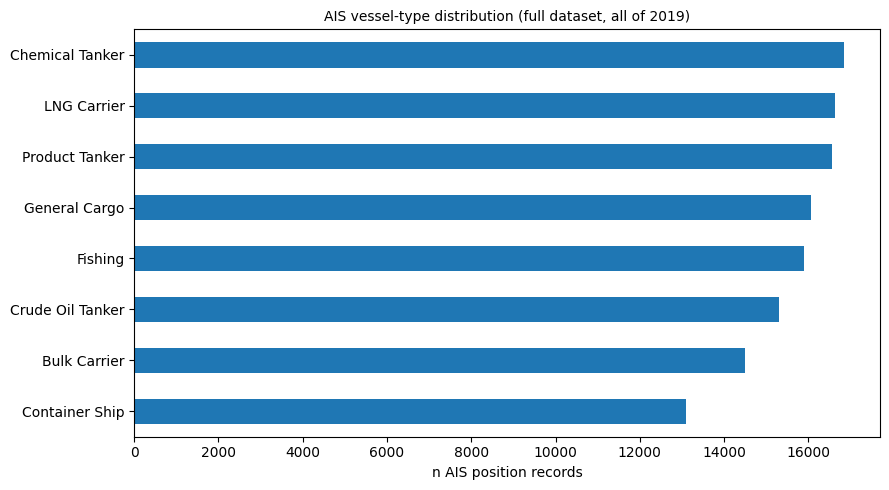

In [3]:
print("vessel_type distribution (full dataset):")
vtype_series = pd.Series(report.vessel_type_counts).sort_values(ascending=False)
print(vtype_series.to_string())

fig, ax = plt.subplots(figsize=(9, 5))
vtype_series.plot(kind="barh", ax=ax)
ax.set_xlabel("n AIS position records")
ax.set_title("AIS vessel-type distribution (full dataset, all of 2019)", fontsize=10)
ax.invert_yaxis()
fig.tight_layout()
fig.savefig(os.path.join(RESULT_DIR, "AIS_vessel_type_distribution_full.png"), dpi=100)
plt.show()

In [4]:
if report.mmsi_with_multiple_names:
    print("MMSI with >1 distinct vessel_name (first 10 shown):")
    for mmsi, names in list(report.mmsi_with_multiple_names.items())[:10]:
        print(f"  mmsi={mmsi}: {names}")
else:
    print("no MMSI has more than one distinct vessel_name")

if report.mmsi_with_multiple_imo:
    print("MMSI with >1 distinct imo (first 10 shown):")
    for mmsi, imos in list(report.mmsi_with_multiple_imo.items())[:10]:
        print(f"  mmsi={mmsi}: {imos}")
else:
    print("no MMSI has more than one distinct imo")

no MMSI has more than one distinct vessel_name
no MMSI has more than one distinct imo


## 2. Write the AIS data quality report to `result/` (requirement 9)

In [5]:
quality_report_lines = [
    "TASK AIS-2 -- AIS data quality report (full dataset)",
    f"source file: {AIS_CSV_PATH}",
    "",
    f"n_rows                      : {report.n_rows}",
    f"n_unique_mmsi               : {report.n_unique_mmsi}",
    f"n_unique_imo                : {report.n_unique_imo}",
    f"n_unique_vessel_name        : {report.n_unique_vessel_name}",
    f"timestamp range             : {report.timestamp_min} .. {report.timestamp_max}",
    f"n_duplicate_rows            : {report.n_duplicate_rows}",
    f"n_duplicate_mmsi_timestamp  : {report.n_duplicate_mmsi_timestamp}",
    f"n_invalid_lat               : {report.n_invalid_lat}",
    f"n_invalid_lon               : {report.n_invalid_lon}",
    f"n_zero_zero_coords          : {report.n_zero_zero_coords}",
    f"n MMSI with >1 distinct vessel_name: {len(report.mmsi_with_multiple_names)}",
    f"n MMSI with >1 distinct imo        : {len(report.mmsi_with_multiple_imo)}",
    "",
    "missing value counts per column:",
] + [f"  {c:15s}: {n}" for c, n in report.missing_value_counts.items()] + [
    "",
    "vessel_type distribution (full dataset):",
] + [f"  {t:30s}: {n}" for t, n in vtype_series.items()]

with open(os.path.join(RESULT_DIR, "AIS_data_quality_report.txt"), "w", encoding="utf-8") as f:
    f.write("\n".join(quality_report_lines))
print("saved AIS_data_quality_report.txt")

saved AIS_data_quality_report.txt


## 3. Extract event-window + AOI records (requirement 2)

In [6]:
windowed = filter_to_event_window(ais_df, T72, T_OBS)
print(f"rows in event window [T72, T0]: {len(windowed)} / {len(ais_df)}")
print(f"distinct MMSI in event window (before AOI filter): {windowed['mmsi'].nunique()}")

event_df = filter_to_aoi(windowed, north=AOI_NORTH, south=AOI_SOUTH, east=AOI_EAST, west=AOI_WEST)
print(f"rows in event window AND project AOI: {len(event_df)} / {len(windowed)}")
print(f"distinct MMSI in event window AND AOI: {event_df['mmsi'].nunique()}")

rows in event window [T72, T0]: 10238 / 124887
distinct MMSI in event window (before AOI filter): 266
rows in event window AND project AOI: 10150 / 10238
distinct MMSI in event window AND AOI: 264


## 4. Build one chronological track per MMSI (requirement 3, 7, 8)

In [7]:
event_tracks = build_vessel_tracks(event_df)
print(f"built {len(event_tracks)} vessel tracks from the event-window+AOI subset")
n_obs_total = sum(t.n_observations for t in event_tracks)
assert n_obs_total == len(event_df)
print(f"total observations across all tracks: {n_obs_total} (matches filtered row count: confirmed)")

obs_counts = np.array([t.n_observations for t in event_tracks])
print(f"observations per track: min={obs_counts.min()}, median={np.median(obs_counts):.1f}, "
      f"mean={obs_counts.mean():.2f}, max={obs_counts.max()}")
n_single_obs = int(np.sum(obs_counts == 1))
print(f"tracks with only 1 observation (no track structure possible): {n_single_obs}")

built 264 vessel tracks from the event-window+AOI subset
total observations across all tracks: 10150 (matches filtered row count: confirmed)
observations per track: min=1, median=37.0, mean=38.45, max=73
tracks with only 1 observation (no track structure possible): 3


## 5. Validate temporal sampling (requirement 4) -- across ALL event tracks

total consecutive-observation intervals measured: 9886
interval hours -- min=1.000 p10=1.000 p25=1.000 median=1.000 p75=1.000 p90=1.000 p95=1.000 p99=1.000 max=8.000
tracks with >=1 gap exceeding 6.0h: 1 / 264


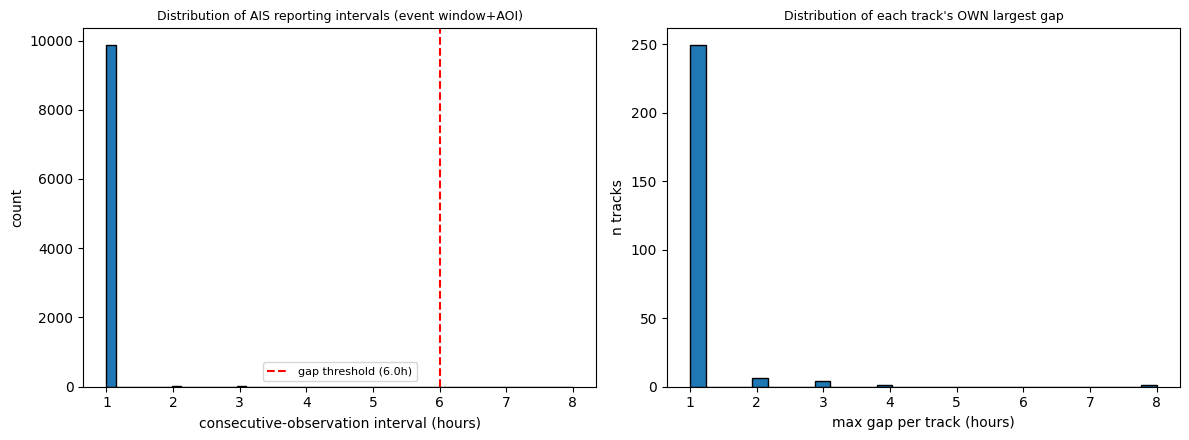

In [8]:
GAP_THRESHOLD_HOURS = 6.0  # explicit, configurable -- see iste.ais_data docstring
all_gaps = [compute_track_temporal_gaps(t, gap_threshold_hours=GAP_THRESHOLD_HOURS) for t in event_tracks]
all_intervals = np.concatenate([g.interval_hours for g in all_gaps if len(g.interval_hours) > 0])
print(f"total consecutive-observation intervals measured: {len(all_intervals)}")
if len(all_intervals) > 0:
    pct = np.percentile(all_intervals, [10, 25, 50, 75, 90, 95, 99])
    print(f"interval hours -- min={all_intervals.min():.3f} p10={pct[0]:.3f} p25={pct[1]:.3f} "
          f"median={pct[2]:.3f} p75={pct[3]:.3f} p90={pct[4]:.3f} p95={pct[5]:.3f} p99={pct[6]:.3f} max={all_intervals.max():.3f}")

n_tracks_with_gap = sum(1 for g in all_gaps if g.n_gaps_over_threshold > 0)
print(f"tracks with >=1 gap exceeding {GAP_THRESHOLD_HOURS}h: {n_tracks_with_gap} / {len(event_tracks)}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].hist(all_intervals, bins=50, edgecolor="black")
axes[0].set_xlabel("consecutive-observation interval (hours)"); axes[0].set_ylabel("count")
axes[0].set_title("Distribution of AIS reporting intervals (event window+AOI)", fontsize=9)
axes[0].axvline(GAP_THRESHOLD_HOURS, color="red", linestyle="--", label=f"gap threshold ({GAP_THRESHOLD_HOURS}h)")
axes[0].legend(fontsize=8)

max_gaps_per_track = np.array([g.max_interval_hours for g in all_gaps if not np.isnan(g.max_interval_hours)])
axes[1].hist(max_gaps_per_track, bins=30, edgecolor="black")
axes[1].set_xlabel("max gap per track (hours)"); axes[1].set_ylabel("n tracks")
axes[1].set_title("Distribution of each track's OWN largest gap", fontsize=9)
fig.tight_layout()
fig.savefig(os.path.join(RESULT_DIR, "AIS_temporal_gap_distribution.png"), dpi=100)
plt.show()

In [9]:
gap_summary_rows = []
for t, g in zip(event_tracks, all_gaps):
    gap_summary_rows.append(dict(
        mmsi=t.mmsi, vessel_name=t.vessel_name, vessel_type=t.vessel_type,
        n_observations=g.n_observations, median_interval_hours=round(g.median_interval_hours, 3) if not np.isnan(g.median_interval_hours) else None,
        max_interval_hours=round(g.max_interval_hours, 3) if not np.isnan(g.max_interval_hours) else None,
        n_gaps_over_threshold=g.n_gaps_over_threshold,
    ))
gap_summary_df = pd.DataFrame(gap_summary_rows)
gap_summary_df.to_csv(os.path.join(RESULT_DIR, "AIS_temporal_gap_summary.csv"), index=False)
print(f"saved AIS_temporal_gap_summary.csv ({len(gap_summary_df)} tracks)")
print(gap_summary_df.sort_values("max_interval_hours", ascending=False).head(10).to_string(index=False))

saved AIS_temporal_gap_summary.csv (264 tracks)
     mmsi        vessel_name      vessel_type  n_observations  median_interval_hours  max_interval_hours  n_gaps_over_threshold
240237003   HELLAS EAGLE V42    General Cargo              17                    1.0                 8.0                      2
352463213     MV PIONEER C81   Product Tanker              17                    1.0                 4.0                      0
370414628 PACIFIC LEADER I47  Chemical Tanker              60                    1.0                 3.0                      0
352456364   MINERVA STAR Y86 Crude Oil Tanker              16                    1.0                 3.0                      0
538826625 PACIFIC SPIRIT O74   Container Ship              20                    1.0                 3.0                      0
636405124    EVER TRADER A72          Fishing              52                    1.0                 3.0                      0
370153472   STENA LEADER C27  Chemical Tanker           

## 6. Validate positional movement (requirement 5) -- across ALL event tracks

In [10]:
all_jumps = []
for t in event_tracks:
    all_jumps.extend(compute_track_positional_jumps(t, max_plausible_speed_knots=DEFAULT_MAX_PLAUSIBLE_SPEED_KNOTS))
print(f"total consecutive-position steps measured: {len(all_jumps)}")

implied_speeds = np.array([j.implied_speed_knots for j in all_jumps if np.isfinite(j.implied_speed_knots)])
if len(implied_speeds) > 0:
    pct = np.percentile(implied_speeds, [50, 90, 95, 99])
    print(f"implied speed (knots) -- median={pct[0]:.2f} p90={pct[1]:.2f} p95={pct[2]:.2f} p99={pct[3]:.2f} max={implied_speeds.max():.2f}")

implausible = [j for j in all_jumps if j.is_implausible]
print(f"flagged implausible jumps (implied speed > {DEFAULT_MAX_PLAUSIBLE_SPEED_KNOTS} knots): {len(implausible)} / {len(all_jumps)}")
print("NONE of these were deleted -- reported here and in AIS_positional_jump_flags.csv only, per this task's own explicit instruction.")

total consecutive-position steps measured: 9886
implied speed (knots) -- median=4.20 p90=7.66 p95=8.94 p99=11.71 max=16.87
flagged implausible jumps (implied speed > 60.0 knots): 0 / 9886
NONE of these were deleted -- reported here and in AIS_positional_jump_flags.csv only, per this task's own explicit instruction.


In [11]:
if implausible:
    jump_rows = [dict(mmsi=j.mmsi, t_prev=str(j.t_prev), t_curr=str(j.t_curr),
                       distance_m=round(j.distance_m, 1), interval_hours=round(j.interval_hours, 4),
                       implied_speed_knots=round(j.implied_speed_knots, 2), reported_sog_knots=j.reported_sog_knots)
                  for j in implausible]
    jump_df = pd.DataFrame(jump_rows).sort_values("implied_speed_knots", ascending=False)
    jump_df.to_csv(os.path.join(RESULT_DIR, "AIS_positional_jump_flags.csv"), index=False)
    print(jump_df.head(15).to_string(index=False))
else:
    jump_df = pd.DataFrame(columns=["mmsi","t_prev","t_curr","distance_m","interval_hours","implied_speed_knots","reported_sog_knots"])
    jump_df.to_csv(os.path.join(RESULT_DIR, "AIS_positional_jump_flags.csv"), index=False)
    print("no implausible jumps found in the event-window+AOI subset")

no implausible jumps found in the event-window+AOI subset


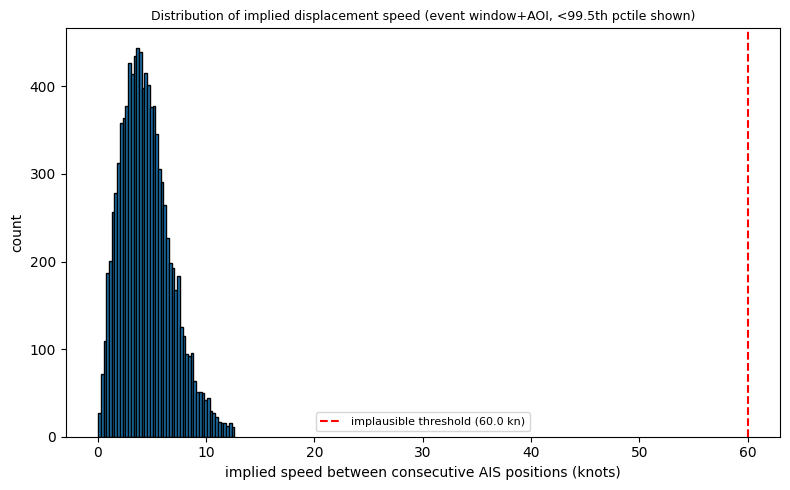

In [12]:
fig, ax = plt.subplots(figsize=(8, 5))
finite_speeds = implied_speeds[implied_speeds < np.percentile(implied_speeds, 99.5)] if len(implied_speeds) else implied_speeds
ax.hist(finite_speeds, bins=50, edgecolor="black")
ax.axvline(DEFAULT_MAX_PLAUSIBLE_SPEED_KNOTS, color="red", linestyle="--", label=f"implausible threshold ({DEFAULT_MAX_PLAUSIBLE_SPEED_KNOTS} kn)")
ax.set_xlabel("implied speed between consecutive AIS positions (knots)"); ax.set_ylabel("count")
ax.set_title("Distribution of implied displacement speed (event window+AOI, <99.5th pctile shown)", fontsize=9)
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(os.path.join(RESULT_DIR, "AIS_implied_speed_distribution.png"), dpi=100)
plt.show()

## 7. SOG/COG vs. observed displacement -- descriptive comparison only (requirement 6)

AIS position + timestamp is treated as the primary observed track; SOG/COG are
metadata carried through unchanged, never used to reconstruct or validate/replace a
position. This cell only DESCRIBES how closely the two agree on this real dataset --
it does not correct, interpolate, or filter anything based on the comparison.

correlation(reported_sog, implied_speed_from_displacement) = -0.019 (descriptive only)


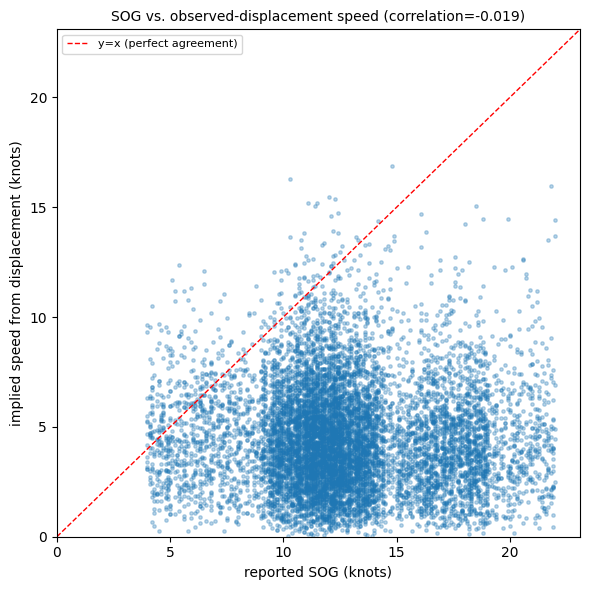

In [13]:
sog_vs_implied = [(j.reported_sog_knots, j.implied_speed_knots) for j in all_jumps if np.isfinite(j.implied_speed_knots)]
if sog_vs_implied:
    sog_arr = np.array([s for s, _ in sog_vs_implied])
    implied_arr = np.array([i for _, i in sog_vs_implied])
    corr = float(np.corrcoef(sog_arr, implied_arr)[0, 1])
    print(f"correlation(reported_sog, implied_speed_from_displacement) = {corr:+.3f} (descriptive only)")
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.scatter(sog_arr, implied_arr, s=6, alpha=0.3)
    lim = max(sog_arr.max(), implied_arr[np.isfinite(implied_arr)].max() if np.any(np.isfinite(implied_arr)) else 0) * 1.05
    ax.plot([0, lim], [0, lim], "r--", linewidth=1, label="y=x (perfect agreement)")
    ax.set_xlabel("reported SOG (knots)"); ax.set_ylabel("implied speed from displacement (knots)")
    ax.set_xlim(0, lim); ax.set_ylim(0, lim)
    ax.set_title(f"SOG vs. observed-displacement speed (correlation={corr:+.3f})", fontsize=10)
    ax.legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(os.path.join(RESULT_DIR, "AIS_sog_vs_implied_speed.png"), dpi=100)
    plt.show()

## 8. Vessel-count-by-type table (requirement 9)

In [14]:
event_vtype_counts = pd.Series([t.vessel_type for t in event_tracks]).value_counts()
print("vessel count by type (event window + AOI, one row per MMSI/track):")
print(event_vtype_counts.to_string())
event_vtype_counts.rename("n_vessels").rename_axis("vessel_type").reset_index().to_csv(
    os.path.join(RESULT_DIR, "AIS_vessel_count_by_type.csv"), index=False,
)
print("saved AIS_vessel_count_by_type.csv")

vessel count by type (event window + AOI, one row per MMSI/track):
Fishing             36
General Cargo       36
Product Tanker      35
LNG Carrier         35
Chemical Tanker     33
Container Ship      31
Crude Oil Tanker    30
Bulk Carrier        28
saved AIS_vessel_count_by_type.csv


## 9. Save the event-window+AOI vessel-track dataset (requirement 9)

In [15]:
track_df = tracks_to_dataframe(event_tracks)
assert len(track_df) == len(event_df)
track_csv_path = os.path.join(RESULT_DIR, "AIS_vessel_tracks_event_window.csv")
track_df.to_csv(track_csv_path, index=False)
print(f"saved {track_csv_path} ({len(track_df)} rows, {track_df['mmsi'].nunique()} vessels)")
try:
    parquet_path = os.path.join(RESULT_DIR, "AIS_vessel_tracks_event_window.parquet")
    track_df.to_parquet(parquet_path, index=False)
    print(f"also saved {parquet_path}")
except Exception as e:
    print(f"parquet engine unavailable ({e}); CSV output above is authoritative")

saved C:\Users\venka\OneDrive\Desktop\SIH-2026\project-v5\result\AIS_vessel_tracks_event_window.csv (10150 rows, 264 vessels)


also saved C:\Users\venka\OneDrive\Desktop\SIH-2026\project-v5\result\AIS_vessel_tracks_event_window.parquet


## 10. Optional: track visualization over the project geographic map

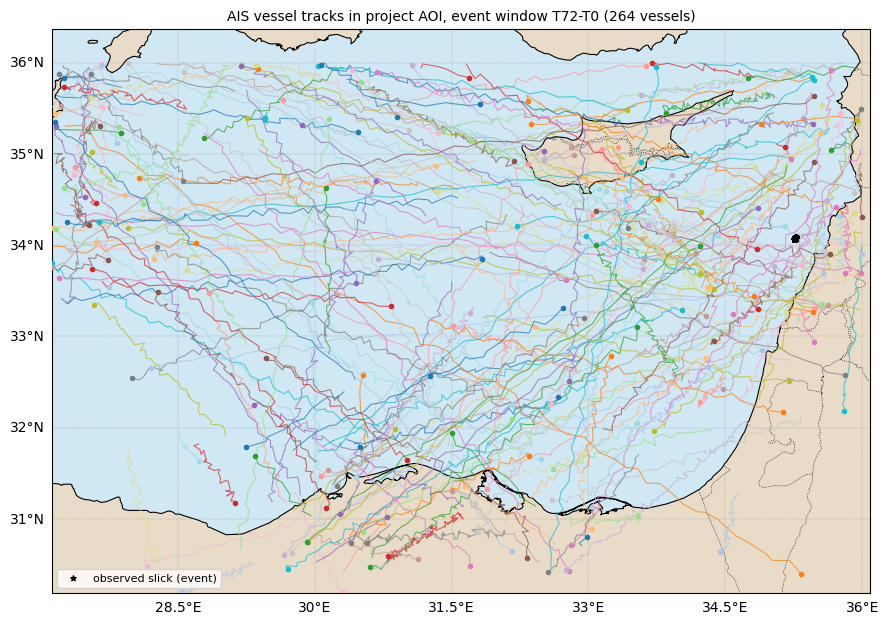

saved AIS_tracks_map.png


In [16]:
try:
    import cartopy.crs as ccrs
    import cartopy.feature as cfeature

    fig, ax = plt.subplots(figsize=(9, 8), subplot_kw={"projection": ccrs.PlateCarree()})
    ax.set_extent([AOI_WEST, AOI_EAST, AOI_SOUTH, AOI_NORTH], crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.NaturalEarthFeature("physical", "ocean", "10m", facecolor="#cfe8f3"), zorder=0)
    ax.add_feature(cfeature.NaturalEarthFeature("physical", "land", "10m", facecolor="#e8dcc8"), zorder=1)
    ax.add_feature(cfeature.COASTLINE.with_scale("10m"), linewidth=0.8, zorder=2)
    ax.add_feature(cfeature.BORDERS.with_scale("10m"), linewidth=0.5, linestyle=":", zorder=2)
    gl = ax.gridlines(draw_labels=True, linewidth=0.3, color="gray", alpha=0.6, linestyle="--")
    gl.top_labels = False; gl.right_labels = False

    cmap = plt.cm.tab20
    for i, t in enumerate(event_tracks):
        c = cmap(i % 20)
        ax.plot(t.lon, t.lat, "-", color=c, linewidth=0.8, alpha=0.7, transform=ccrs.PlateCarree(), zorder=4)
        ax.plot(t.lon[-1], t.lat[-1], "o", color=c, markersize=3, transform=ccrs.PlateCarree(), zorder=5)

    # mark the observed slick / event location for context
    import json as _json
    spill_data = _json.load(open(os.path.join(REPO_ROOT, "data", "database_payload.json"), encoding="utf-8"))
    spill = next(s for s in spill_data["spills"] if s["image_filename"] == "ow-0008.jpg")
    parcels = spill["parcels"]
    obs_lat = np.array([p["lat"] for p in parcels]); obs_lon = np.array([p["lon"] for p in parcels])
    ax.scatter(obs_lon, obs_lat, s=15, c="black", marker="*", transform=ccrs.PlateCarree(), zorder=6, label="observed slick (event)")

    ax.set_title(f"AIS vessel tracks in project AOI, event window T72-T0 ({len(event_tracks)} vessels)", fontsize=10)
    ax.legend(fontsize=8, loc="lower left")
    fig.tight_layout()
    fig.savefig(os.path.join(RESULT_DIR, "AIS_tracks_map.png"), dpi=110)
    plt.show()
    print("saved AIS_tracks_map.png")
except ImportError as e:
    print(f"cartopy unavailable ({e}); skipping optional map visualization")

## 11. Event-window summary + final report (requirement 9, 10)

In [17]:
n_vessels_in_window_before_aoi = int(windowed["mmsi"].nunique())
n_vessels_in_aoi_and_window = len(event_tracks)
n_observations = len(event_df)
n_usable_tracks = int(np.sum(obs_counts >= 2))  # >=2 observations needed for any track/displacement structure
n_tracks_with_large_gaps = n_tracks_with_gap

summary_lines = [
    "TASK AIS-2 -- AIS event-window summary",
    f"event window: T72={T72} .. T0={T_OBS}",
    f"project AOI: N={AOI_NORTH} W={AOI_WEST} S={AOI_SOUTH} E={AOI_EAST}",
    "",
    f"vessels with >=1 AIS position inside the event window (before AOI filter): {n_vessels_in_window_before_aoi}",
    f"vessels entering the AOI during the event window: {n_vessels_in_aoi_and_window}",
    f"AIS observations in event window + AOI: {n_observations}",
    f"usable tracks (>=2 observations, displacement computable): {n_usable_tracks}",
    f"single-observation tracks (no track structure possible): {n_single_obs}",
    f"tracks with >=1 gap exceeding {GAP_THRESHOLD_HOURS}h: {n_tracks_with_large_gaps}",
    f"flagged implausible positional jumps (>{DEFAULT_MAX_PLAUSIBLE_SPEED_KNOTS} knots implied speed): {len(implausible)}",
    f"duplicate (mmsi, timestamp) records in FULL dataset: {report.n_duplicate_mmsi_timestamp}",
    f"invalid lat/lon in FULL dataset: {report.n_invalid_lat} / {report.n_invalid_lon}",
]
print("\n".join(summary_lines))
with open(os.path.join(RESULT_DIR, "AIS_event_window_summary.txt"), "w", encoding="utf-8") as f:
    f.write("\n".join(summary_lines))
print()
print("saved AIS_event_window_summary.txt")

TASK AIS-2 -- AIS event-window summary
event window: T72=2019-06-11 20:35:58+00:00 .. T0=2019-06-14 20:35:58+00:00
project AOI: N=36.372 W=27.121 S=30.1875 E=36.088

vessels with >=1 AIS position inside the event window (before AOI filter): 266
vessels entering the AOI during the event window: 264
AIS observations in event window + AOI: 10150
usable tracks (>=2 observations, displacement computable): 261
single-observation tracks (no track structure possible): 3
tracks with >=1 gap exceeding 6.0h: 1
flagged implausible positional jumps (>60.0 knots implied speed): 0
duplicate (mmsi, timestamp) records in FULL dataset: 0
invalid lat/lon in FULL dataset: 0 / 0



saved AIS_event_window_summary.txt


## 12. Validation checklist

In [18]:
checks = []
checks.append(("all event-window+AOI rows accounted for in tracks", sum(t.n_observations for t in event_tracks) == len(event_df)))
checks.append(("no candidate ranking/AIS score computed anywhere in this notebook", "ais_score" not in dir()))
checks.append(("iste.phase3_ais / iste.phase3_composite not imported", "phase3_ais" not in sys.modules and "phase3_composite" not in sys.modules))
checks.append(("output files written under result/", os.path.exists(track_csv_path)))
checks.append(("event window matches T27's own T0/T72 exactly", str(T_OBS)[:19] == "2019-06-14 20:35:58" and str(T72)[:19] == "2019-06-11 20:35:58"))
for label, ok in checks:
    print(f"[{'OK' if ok else 'FAIL'}] {label}")
assert all(ok for _, ok in checks)

output_files = sorted(f for f in os.listdir(RESULT_DIR) if f.startswith("AIS_"))
print(f"\n{len(output_files)} AIS_* files saved under {RESULT_DIR}:")
for fn in output_files:
    size_kb = os.path.getsize(os.path.join(RESULT_DIR, fn)) / 1024
    print(f"  {fn}  ({size_kb:.1f} KB)")

[OK] all event-window+AOI rows accounted for in tracks
[OK] no candidate ranking/AIS score computed anywhere in this notebook
[OK] iste.phase3_ais / iste.phase3_composite not imported
[OK] output files written under result/
[OK] event window matches T27's own T0/T72 exactly

12 AIS_* files saved under C:\Users\venka\OneDrive\Desktop\SIH-2026\project-v5\result:
  AIS_data_quality_report.txt  (1.3 KB)
  AIS_event_window_summary.txt  (0.7 KB)
  AIS_implied_speed_distribution.png  (24.4 KB)
  AIS_positional_jump_flags.csv  (0.1 KB)
  AIS_sog_vs_implied_speed.png  (142.7 KB)
  AIS_temporal_gap_distribution.png  (29.8 KB)
  AIS_temporal_gap_summary.csv  (14.2 KB)
  AIS_tracks_map.png  (609.5 KB)
  AIS_vessel_count_by_type.csv  (0.2 KB)
  AIS_vessel_tracks_event_window.csv  (1140.0 KB)
  AIS_vessel_tracks_event_window.parquet  (254.6 KB)
  AIS_vessel_type_distribution_full.png  (24.2 KB)
